In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
print(os.getcwd())

/Users/arneetkaurgill/phishing-classifier


In [2]:
import ssl, certifi
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())

In [3]:
import os, pandas as pd

if os.path.exists('data/phishing.csv'):
    df = pd.read_csv('data/phishing.csv')
else:
    from ucimlrepo import fetch_ucirepo
    data = fetch_ucirepo(id=327)
    df = data.data.features.copy()
    df['result'] = data.data.targets['result']
    os.makedirs('data', exist_ok=True)
    df.to_csv('data/phishing.csv', index=False)

print("Shape:", df.shape)

Shape: (11055, 31)


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression

df = pd.read_csv('data/phishing.csv')
print("Before:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", df.shape)
print(df['result'].value_counts())

X = df.drop(columns='result')
y = (df['result'] == -1).astype(int)   # 1 = phishing, 0 = legitimate

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("\nTrain:", X_train.shape, " Test:", X_test.shape)
print("Phishing share  train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

# Baseline model, scored with 5-fold cross-validation on the training set only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baseline = LogisticRegression(max_iter=1000)
for metric in ['accuracy', 'precision', 'recall', 'f1']:
    scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring=metric)
    print(f"{metric:10s} {scores.mean():.4f} (+/- {scores.std():.4f})")

Before: (11055, 31)
After removing duplicates: (5849, 31)
result
-1    3019
 1    2830
Name: count, dtype: int64

Train: (4679, 30)  Test: (1170, 30)
Phishing share  train: 0.516  test: 0.516
accuracy   0.9211 (+/- 0.0022)
precision  0.9293 (+/- 0.0089)
recall     0.9172 (+/- 0.0101)
f1         0.9231 (+/- 0.0023)


In [5]:
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=['accuracy', 'precision', 'recall', 'f1'])
    rows.append({
        "model": name,
        "accuracy": res['test_accuracy'].mean(),
        "precision": res['test_precision'].mean(),
        "recall": res['test_recall'].mean(),
        "f1": res['test_f1'].mean(),
    })

results = pd.DataFrame(rows).set_index("model").round(4).sort_values("f1", ascending=False)
results

,accuracy,precision,recall,f1
model,,,,
Gradient Boosting,0.9506,0.9525,0.9520,0.9522
Random Forest,0.9479,0.9553,0.9433,0.9492
Logistic Regression,0.9211,0.9293,0.9172,0.9231
Decision Tree,0.9199,0.9276,0.9164,0.9219


In [6]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'learning_rate': [0.03, 0.05, 0.1, 0.2],
    'max_iter': [100, 200, 300, 500],
    'max_depth': [None, 3, 5, 8],
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [10, 20, 40],
    'l2_regularization': [0, 0.1, 1.0],
}

search = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    param_dist, n_iter=25, cv=cv, scoring='f1',
    random_state=42, n_jobs=-1
)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Best cross-validated F1:", round(search.best_score_, 4))
best_model = search.best_estimator_

Best settings: {'min_samples_leaf': 40, 'max_leaf_nodes': 15, 'max_iter': 200, 'max_depth': 5, 'learning_rate': 0.1, 'l2_regularization': 0}
Best cross-validated F1: 0.9553


              precision    recall  f1-score   support

  legitimate     0.9528    0.9629    0.9578       566
    phishing     0.9649    0.9553    0.9601       604

    accuracy                         0.9590      1170
   macro avg     0.9588    0.9591    0.9589      1170
weighted avg     0.9590    0.9590    0.9590      1170

ROC-AUC: 0.9935


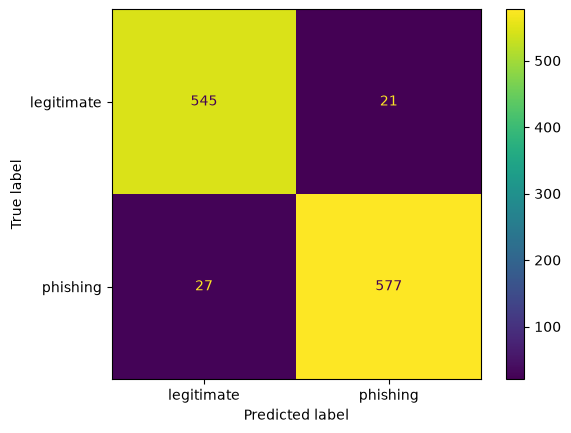

In [7]:
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred,
      target_names=['legitimate', 'phishing'], digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['legitimate', 'phishing'])
plt.show()

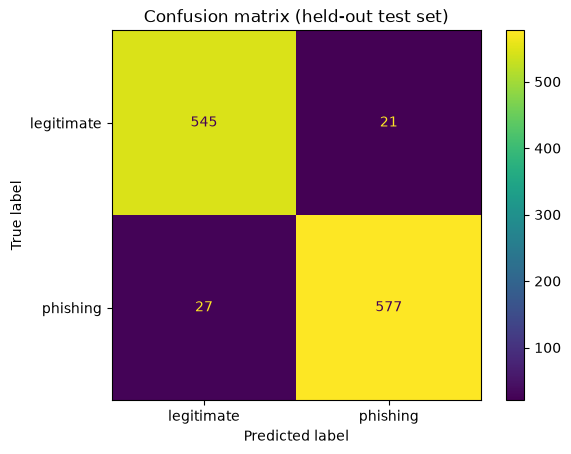

url_of_anchor             0.1119
sslfinal_state            0.0958
prefix_suffix             0.0318
web_traffic               0.0239
links_in_tags             0.0162
links_pointing_to_page    0.0154
sfh                       0.0148
having_ip_address         0.0145
having_sub_domain         0.0142
page_rank                 0.0089
dtype: float64


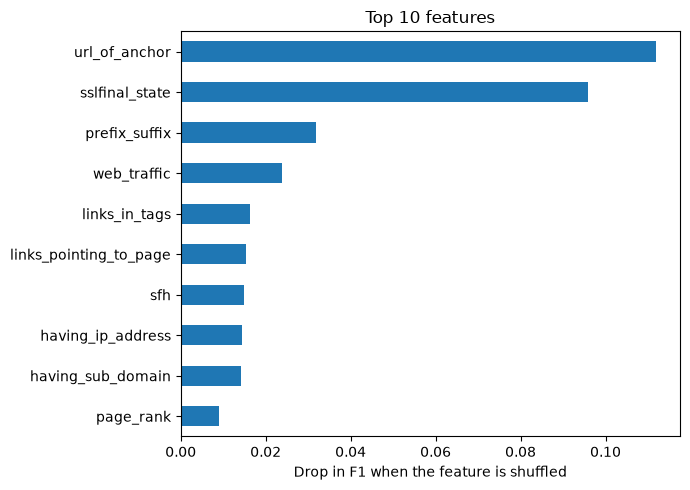

['models/phishing_model.joblib']

In [8]:
from sklearn.inspection import permutation_importance
import joblib, os

os.makedirs('reports', exist_ok=True)
os.makedirs('models', exist_ok=True)

# Confusion matrix, saved as an image
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['legitimate', 'phishing'])
plt.title('Confusion matrix (held-out test set)')
plt.savefig('reports/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Which features matter most: how much F1 drops when each one is shuffled
r = permutation_importance(best_model, X_test, y_test, scoring='f1',
                           n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp.head(10).round(4))

plt.figure(figsize=(7, 5))
imp.head(10).iloc[::-1].plot.barh()
plt.xlabel('Drop in F1 when the feature is shuffled')
plt.title('Top 10 features')
plt.tight_layout()
plt.savefig('reports/feature_importance.png', dpi=150)
plt.show()

joblib.dump(best_model, 'models/phishing_model.joblib')

In [9]:
print(search.best_params_)

{'min_samples_leaf': 40, 'max_leaf_nodes': 15, 'max_iter': 200, 'max_depth': 5, 'learning_rate': 0.1, 'l2_regularization': 0}


In [10]:
for k, v in search.best_params_.items():
    print(k, "=", v)
print("Best CV F1:", round(search.best_score_, 4))

min_samples_leaf = 40
max_leaf_nodes = 15
max_iter = 200
max_depth = 5
learning_rate = 0.1
l2_regularization = 0
Best CV F1: 0.9553
